# Benchmarking wildfire spread models

**SCIL, AI Collaborative for Wildfire, Workstream 2.** November 2026.

This notebook is the whole interface to the framework. It has two halves:

* a **fire modeling workflow**: a recipe for predicting a fire (which data, which **methods** alter it, which model, which settings), with no fire in it. It turns a fire's facts into **fire rasters** (time of arrival, intensity);
* **benchmarking**: taking those fire rasters and scoring them against a **reference**, what the fire really did. Across fires and modeling workflows, the scores form a **scoring matrix**.

The fires are **cases**, each with its facts (when it started, where, its ignition points, its observed perimeters). Every step records in Dagster how its output was produced, and every finished artifact is also copied to S3.

The example fires are four 2025 California fires, each scored against a FIRIS perimeter about two to three hours after discovery, at the time that perimeter was observed:

| Fire | When, where | Observed |
|---|---|---|
| **Hughes** | Jan 22, Lake Hughes Rd near Castaic Lake, Los Angeles County | 5,043 acres at 147 min |
| **Kenneth** | Jan 9, West Hills / Calabasas, Los Angeles / Ventura counties | 960 acres at 165 min |
| **Madre** | Jul 2, San Luis Obispo County (Los Padres NF) | 8,396 acres at 161 min |
| **Sandia** | Oct 7, San Diego County | 30 acres at 118 min |

The modeling workflow runs ELMFIRE on real LANDFIRE fuels and real station wind.

| Section | What happens |
|---|---|
| **Fire modeling workflow** | |
| 1. The recipe | The workflow file |
| 2. The fires | The case files |
| 3. From recipe to plan | The resolver checks the recipe against the block registry and plans it for each fire |
| 4. The graph | The plan as the asset graph Dagster will run |
| 5. Identity and reuse | Why the same LANDFIRE is never downloaded twice |
| 6. Compile and push | The plan becomes one file on the WSTC Dagster |
| 7. Run it on the fires | One Dagster run per fire |
| **Benchmarking** | |
| 8. The scores | Scores, previews, raster downloads, and where to look in Dagster |
| 9. A second modeling workflow | A different ignition source: what is shared, and the scoring matrix |
| 10. Models we don't run | Submitting predictions instead of code; open vs closed models |
| 11. What is real so far | An honest list |


## 0. Setup

The notebook runs anywhere that can reach the WSTC Dagster over HTTPS: a laptop, or NDP JupyterHub. It needs this repository (block registry, resolver, compiler) plus `pyyaml` and `requests`.

Two things are never stored in the notebook: the WSTC dashboard password (typed in), and an email address for LANDFIRE's download service, which requires one on every request (read from `BENCH_LFPS_EMAIL`, set in the environment or in the git-ignored `.bench.local`, or typed in; it travels as a run tag).

In [1]:
import os, sys, getpass, time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(REPO / "src"), str(REPO / "deploy" / "wstc")]

from bench import wstc
from bench.workflows import load_workflow, load_cases
from bench.notebook import (show_file, plan_tables, mermaid, identity_table, shared_with, md_table,
                            run_fires, asset_rows, show_previews, scoring_matrix, download_links)
from dagster_client import Dagster
from IPython.display import display, Markdown

ME = "apearce"                       # everything we put on the shared server starts with this
WORKFLOW = REPO / "workflows" / "elmfire_reported_ignition.yaml"
FIRES = ["hughes", "kenneth", "madre", "sandia"]   # cases/<name>.yaml; None = every case
IMAGES = wstc.image_refs("a3pearce") # the blocks' images, one per family (section 6)
BUILD = REPO / "deploy" / "wstc" / "build"     # compiled files land here (not committed)
BUILD.mkdir(exist_ok=True)

# personal settings live in a local, git-ignored file (REPO/.bench.local, lines like
# BENCH_LFPS_EMAIL=you@example.org), so they are never typed into the notebook's output
LOCAL = REPO / ".bench.local"
for line in (LOCAL.read_text().splitlines() if LOCAL.exists() else []):
    key, _, value = line.partition("=")
    if key.strip() and not key.strip().startswith("#"):
        os.environ.setdefault(key.strip(), value.strip())

In [2]:
d = Dagster(password=getpass.getpass("WSTC Dagster password: "))
LFPS_EMAIL = os.environ.get("BENCH_LFPS_EMAIL") or input("Email for LANDFIRE requests: ").strip()
print(len(d.jobs()), "jobs on the server")

WSTC Dagster password:  ········


9 jobs on the server


## 1. The recipe

A workflow is configuration only. Each **input slot** (landscape, weather, moisture, ignition) has exactly one **source**, optionally followed by **methods**: anything that alters the slot's data, from a simple rule (roads and urban cells to a burnable fuel) to an ML model; then one **model** with fixed parameters, a **reference** and the **metrics**. Every name is a **block**: a manifest in `blocks/` declaring what it consumes and produces and which parameters it takes.

There is no fire in it. The ignition source says "the case's *reported* ignition", not a coordinate.

In [3]:
show_file(WORKFLOW)

```yaml
# ELMFIRE from the reported ignition point, on LANDFIRE 2024 fuels with a roads override,
# hourly wind from the nearest ASOS station (uniform; no WindNinja yet) and a fixed 6%
# 1-h dead fuel moisture.
#
# A workflow is a recipe: one source per input slot, one model with fixed parameters.
# No fire in it: cases/ holds the fires, and the request picks which ones to run.
# A different version of the recipe is a different workflow (see elmfire_ngfs_ignition.yaml).

grid:
  resolution_m: 30                  # the working grid's cell size (LANDFIRE's native)

inputs:
  landscape:
    source: {block: landfire, version: "2024", layers: [fbfm40, cc, ch, cbh, cbd, elevation]}
    methods:                        # applied in order to the source's output
      - {block: roads_override}
  weather:
    source: {block: station_wind}
  moisture:
    source: {block: fixed_moisture, params: {dead_1h: 0.06}}
  ignition:
    source: {block: case_ignition, params: {which: reported}}

model: {block: elmfire, params: {duration_min: 180}}   # scored at each reference's observation time (<= 180 min)

reference: {block: final_perimeter}           # the case's reference perimeter
metrics: [{block: iou}, {block: area_bias}]
```

## 2. The fires

A case is one fire's facts: its clock zero (`t0`), weather window, domain, ignition points and observed perimeter. The framework derives each fire's working grid from it (EPSG:5070 at the recipe's 30 m).

In [4]:
for name in FIRES or sorted(load_cases()):
    show_file(REPO / "cases" / f"{name}.yaml")

```yaml
# The Hughes Fire, Jan 22 2025: Lake Hughes Rd near Castaic Lake, Los Angeles County
# (Angeles NF; 10,425 acres at containment, CAL FIRE). Built from the WIFIRE Consolidated
# Fire Groupings 2025 geopackage, fire_group 13_CA-ANF-UNKNOWN-20250122-1040_HUGHES-N40Y.
#
# A case is one fire's facts; workflows (recipes) run on it. See cases/README.md.
incident: HUGHES
t0: "2025-01-22T18:37:24Z"          # simulation clock zero (UTC): IRWIN discovery (2025-CAANF-250270)
window_h: 24                         # hours of weather to fetch from t0
# no domain_wgs84: the domain is the reference perimeter's bounding box + domain_buffer_km (5 km)

ignitions:                           # each is a source a workflow can pick (case_ignition, which: <name>)
  reported:                          # the ignition the earlier benchmark used (geopackage Centers layer)
    {lat: 34.576532, lon: -118.556428, time_utc: "2025-01-22T18:40:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, Centers (fire_start)"}
  ngfs:                              # first NGFS (GOES) detection; NGFS times are Pacific, converted to UTC
    {lat: 34.578626, lon: -118.555745, time_utc: "2025-01-22T18:41:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, NGFS (first detection 10:41 PST)"}
  calfire:                           # the CAL FIRE incident page's origin (no workflow uses it yet)
    {lat: 34.553008, lon: -118.56687, time_utc: "2025-01-22T18:53:00Z",
     source: "CAL FIRE incident page (reported 10:53 PST)"}

reference:                           # the observed perimeter to score against
  file: references/hughes_perimeter.geojson
  observed_utc: "2025-01-22T21:04:31Z"   # the latest perimeter in the geopackage: 5,043 acres, 147 min after t0
  source: "FIRIS perimeter (geopackage Perimeters id 14616)"
```

```yaml
# The Kenneth Fire, Jan 9 2025: West Hills / Calabasas, on the Los Angeles / Ventura county line.
# Built from the WIFIRE Consolidated Fire Groupings 2025 geopackage,
# fire_group 8_CA-VNC-KENNETH-20240109-1428_None.
#
# A case is one fire's facts; workflows (recipes) run on it. See cases/README.md.
incident: KENNETH
t0: "2025-01-09T22:39:23Z"          # simulation clock zero (UTC): the earliest of the fire's three IRWIN
                                     # records (2025-CALAC-012267; also 2025-CAVNC-003155, 2025-CALFD-000003)
window_h: 24
# no domain_wgs84: the domain is the reference perimeter's bounding box + domain_buffer_km (5 km)

ignitions:
  reported:                          # the geopackage Centers layer (fire_start)
    {lat: 34.184187, lon: -118.670197, time_utc: "2025-01-09T22:47:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, Centers (fire_start)"}
  ngfs:                              # first NGFS (GOES) detection; NGFS times are Pacific, converted to UTC
    {lat: 34.185697, lon: -118.670986, time_utc: "2025-01-09T22:46:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, NGFS (first detection 14:46 PST)"}

reference:
  file: references/kenneth_perimeter.geojson
  observed_utc: "2025-01-10T01:24:12Z"   # the latest FIRIS mapping (mission 01:13Z): 960 acres, 165 min after t0
  source: "FIRIS perimeter (geopackage Perimeters id 14511)"
```

```yaml
# The Madre Fire, Jul 2 2025: San Luis Obispo County (Los Padres NF), along Hwy 166.
# Built from the WIFIRE Consolidated Fire Groupings 2025 geopackage,
# fire_group 63_CA-SLU-GILARDI-20250702-1312_MADRE-N57B.
#
# A case is one fire's facts; workflows (recipes) run on it. See cases/README.md.
incident: MADRE
t0: "2025-07-02T20:07:32Z"          # simulation clock zero (UTC): IRWIN discovery (2025-CALPF-001817)
window_h: 24
# no domain_wgs84: the domain is the reference perimeter's bounding box + domain_buffer_km (5 km)

ignitions:
  reported:                          # the geopackage Centers layer (fire_start)
    {lat: 35.094912, lon: -120.03572, time_utc: "2025-07-02T20:12:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, Centers (fire_start)"}
  ngfs:                              # first NGFS (GOES) detection; NGFS times are Pacific, converted to UTC.
                                     # 1.5 min before the IRWIN discovery: the model starts it at t0
    {lat: 35.094444, lon: -120.036667, time_utc: "2025-07-02T20:06:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, NGFS (first detection 13:06 PDT)"}

reference:
  file: references/madre_perimeter.geojson
  observed_utc: "2025-07-02T22:48:21Z"   # the later of the two perimeters: 8,396 acres, 161 min after t0
  source: "FIRIS perimeter (geopackage Perimeters id 14727)"
```

```yaml
# The Sandia Fire, Oct 7 2025: San Diego County (CAL FIRE San Diego unit, ~23-30 acres).
# Built from the WIFIRE Consolidated Fire Groupings 2025 geopackage,
# fire_group 145_CA-SDU-SANDIA-20251007-1551_None.
#
# A case is one fire's facts; workflows (recipes) run on it. See cases/README.md.
incident: SANDIA
t0: "2025-10-07T22:20:06Z"          # simulation clock zero (UTC): IRWIN discovery (2025-CASDU-021862)
window_h: 24
# no domain_wgs84: the domain is the reference perimeter's bounding box + domain_buffer_km (5 km)

ignitions:
  reported:                          # the ignition the earlier benchmark used (geopackage Centers layer)
    {lat: 33.446984, lon: -117.262573, time_utc: "2025-10-07T22:51:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, Centers (fire_start)"}
  ngfs:                              # first NGFS (GOES) detection; NGFS times are Pacific, converted to UTC
    {lat: 33.450001, lon: -117.26667, time_utc: "2025-10-07T22:46:00Z",
     source: "WIFIRE Consolidated Fire Groupings 2025, NGFS (first detection 15:46 PDT)"}

reference:
  file: references/sandia_perimeter.geojson
  observed_utc: "2025-10-08T00:18:00Z"   # "sandia4": 30.4 acres, 118 min after t0 (the last valid perimeter)
  source: "FIRIS perimeter (geopackage Perimeters id 14868)"
```

## 3. From recipe to plan

The **resolver** applies the recipe to each fire before anything runs. It checks every block exists, is the right kind for where it is used and has an implementation; checks every parameter's type and merges it with the manifest's defaults; inserts automatic steps where a source's native CRS differs from the fire's (the ignition comes in as lat/lon, so it gets a reproject step); and checks the model's required inputs are all produced. A recipe that can't work is rejected here, not two hours into a run.

What can differ from fire to fire (an ignition source the case doesn't have, no weather station in range) is found when the step runs, and recorded as *unavailable*, with the reason (section 9).

In [5]:
cp = wstc.compile_plan(load_workflow(WORKFLOW), load_cases(FIRES), ME)
plan_tables(cp)

**Steps** (one asset each, partitioned by fire; one pod per step)

| slot | step | block | kind | image | why inserted |
|---|---|---|---|---|---|
| landscape | landscape.landfire | landfire | source | bench-core |  |
| landscape | landscape.roads_override | roads_override | method | bench-core |  |
| weather | weather.station_wind | station_wind | source | bench-core |  |
| moisture | moisture.fixed_moisture | fixed_moisture | source | bench-core |  |
| ignition | ignition.case_ignition | case_ignition | source | bench-core |  |
| ignition | ignition.auto_reproject | reproject | auto | bench-core | native CRS EPSG:4326 differs from case CRS EPSG:5070 |

**Model:** `elmfire` with `{"spread_adjustment": 1.5, "duration_min": 180, "band_duration_min": 60}` (image `bench-elmfire`)  
**Reference:** `final_perimeter`  
**Metrics:** `iou`, `area_bias`

**Fires**

| fire | domain (W, S, E, N) | t0 | reference |
|---|---|---|---|
| hughes | [-118.67428, 34.48548, -118.49081, 34.62473] | 2025-01-22T18:37:24Z | local file |
| kenneth | [-118.75673, 34.11596, -118.61504, 34.23281] | 2025-01-09T22:39:23Z | local file |
| madre | [-120.10265, 35.02861, -119.87984, 35.16616] | 2025-07-02T20:07:32Z | local file |
| sandia | [-117.32415, 33.39735, -117.20459, 33.49478] | 2025-10-07T22:20:06Z | local file |

## 4. The graph

Each node's badge says what kind of block it is (source, method, model, reference, metric). Every asset is partitioned by fire, so running the recipe on one fire is one Dagster run, and Dagster can chart any number (burned area, IoU) across fires. The fire modeling workflow ends at `prediction` (the fire rasters); `reference` and `score/*` are the benchmarking, and `report` gathers the table.

In [6]:
mermaid(cp)

```mermaid
flowchart LR
  n0["<b>landscape</b><br/>landfire"]:::step
  n1["<b>landscape</b><br/>roads_override"]:::step
  n0 --> n1
  n2["<b>weather</b><br/>station_wind"]:::step
  n3["<b>moisture</b><br/>fixed_moisture"]:::step
  n4["<b>ignition</b><br/>case_ignition"]:::step
  n5["<b>ignition</b><br/>reproject"]:::step
  n4 --> n5
  n6["<b>prediction</b><br/>elmfire"]:::step
  n1 --> n6
  n2 --> n6
  n3 --> n6
  n5 --> n6
  n7["<b>reference</b><br/>observed perimeter"]:::step
  n8["<b>report</b><br/>one row per fire"]:::step
  n9["<b>score</b><br/>iou"]:::step
  n6 --> n9
  n7 --> n9
  n9 --> n8
  n10["<b>score</b><br/>area_bias"]:::step
  n6 --> n10
  n7 --> n10
  n10 --> n8
  classDef step fill:#fde3c8,stroke:#c2410c,color:#111
```

_No diagram above? Your Jupyter is older than JupyterLab 4.1; [open it in the Mermaid viewer](https://mermaid.live/view#base64:eyJjb2RlIjogImZsb3djaGFydCBMUlxuICBuMFtcIjxiPmxhbmRzY2FwZTwvYj48YnIvPmxhbmRmaXJlXCJdOjo6c3RlcFxuICBuMVtcIjxiPmxhbmRzY2FwZTwvYj48YnIvPnJvYWRzX292ZXJyaWRlXCJdOjo6c3RlcFxuICBuMCAtLT4gbjFcbiAgbjJbXCI8Yj53ZWF0aGVyPC9iPjxici8-c3RhdGlvbl93aW5kXCJdOjo6c3RlcFxuICBuM1tcIjxiPm1vaXN0dXJlPC9iPjxici8-Zml4ZWRfbW9pc3R1cmVcIl06OjpzdGVwXG4gIG40W1wiPGI-aWduaXRpb248L2I-PGJyLz5jYXNlX2lnbml0aW9uXCJdOjo6c3RlcFxuICBuNVtcIjxiPmlnbml0aW9uPC9iPjxici8-cmVwcm9qZWN0XCJdOjo6c3RlcFxuICBuNCAtLT4gbjVcbiAgbjZbXCI8Yj5wcmVkaWN0aW9uPC9iPjxici8-ZWxtZmlyZVwiXTo6OnN0ZXBcbiAgbjEgLS0-IG42XG4gIG4yIC0tPiBuNlxuICBuMyAtLT4gbjZcbiAgbjUgLS0-IG42XG4gIG43W1wiPGI-cmVmZXJlbmNlPC9iPjxici8-b2JzZXJ2ZWQgcGVyaW1ldGVyXCJdOjo6c3RlcFxuICBuOFtcIjxiPnJlcG9ydDwvYj48YnIvPm9uZSByb3cgcGVyIGZpcmVcIl06OjpzdGVwXG4gIG45W1wiPGI-c2NvcmU8L2I-PGJyLz5pb3VcIl06OjpzdGVwXG4gIG42IC0tPiBuOVxuICBuNyAtLT4gbjlcbiAgbjkgLS0-IG44XG4gIG4xMFtcIjxiPnNjb3JlPC9iPjxici8-YXJlYV9iaWFzXCJdOjo6c3RlcFxuICBuNiAtLT4gbjEwXG4gIG43IC0tPiBuMTBcbiAgbjEwIC0tPiBuOFxuICBjbGFzc0RlZiBzdGVwIGZpbGw6I2ZkZTNjOCxzdHJva2U6I2MyNDEwYyxjb2xvcjojMTExIiwgIm1lcm1haWQiOiB7InRoZW1lIjogImRlZmF1bHQifX0=)._

### Conventions at every block boundary

Models disagree about almost everything: which way is north in an array, whether wind direction is where it blows from or to, whether canopy cover is a percent or a fraction. The framework fixes one answer for each (`docs/conventions.md`), makes every block convert in and out of it, and checks every raster a block writes before accepting it.

| Rule | Value |
|---|---|
| Grid | the fire's CRS (EPSG:5070) at the recipe's resolution, **north-up**: row 0 is the northern edge |
| Wind direction | degrees clockwise from **grid** north, the direction the wind blows **from** |
| Units | SI: m, m/s, kg/m³, canopy cover as a fraction |
| Time | minutes since the fire's t0; arrival time NaN = never burned |

Two examples from this run: the station-wind block rotates directions from true north to grid north (by 13.7° here: Castaic is about 23° of longitude west of EPSG:5070's central meridian at 96° W, and this Albers projection turns grid north about 0.6° per degree of longitude; without the rotation a Santa Ana from 60° would be fed to the model as one from 46°), and the ELMFIRE adapter flips every grid on the way in and out, because pyretechnics puts row 0 at the **south** edge.

## 5. Identity and reuse

Every artifact gets an **identity**: a hash of everything that determines its content (the block's code, version, parameters and data selection, the facts of the fire it depends on, and its inputs' identities), and is stored under it, not under the workflow's name. Before a step does any work it checks whether its identity is already built.

So every recipe that uses the same LANDFIRE on the same fire shares one download. LANDFIRE's identity only depends on the fire's grid, not on, say, its ignition time. Change anything that matters (the domain, a parameter, the block's code) and the identity changes: nothing stale is ever served.

Every finished artifact is also copied to S3 under the same identity path, so the record of what was built, and the data itself, outlive the shared server.

In [7]:
identity_table(cp, (FIRES or sorted(cp["fires"]))[0])

| step | identity | artifact (shared volume) |
|---|---|---|
| landscape.landfire | ebe22ed133 | hughes/landscape/landfire-ebe22ed133 |
| landscape.roads_override | bdec15e267 | hughes/landscape/roads_override-bdec15e267 |
| weather.station_wind | 0611023d0c | hughes/weather/station_wind-0611023d0c |
| moisture.fixed_moisture | 2f99900062 | hughes/moisture/fixed_moisture-2f99900062 |
| ignition.case_ignition | 44635a5124 | hughes/ignition/case_ignition-44635a5124 |
| ignition.auto_reproject | 226464c66d | hughes/ignition/reproject-226464c66d |
| reference | b5265e0bb1 | hughes/reference/final_perimeter-b5265e0bb1 |
| prediction | 448fd60ec6 | hughes/runs/elmfire-448fd60ec6 |

## 6. Compile and push

The WSTC server takes **one Python file per upload**, and its standard image has only a handful of packages. So the workflow is compiled into one file, **`apearce_elmfire_reported_ignition.py`**: the plan for every fire plus the blocks' code.

The blocks' packages come from **container images** on Docker Hub, one per family of blocks with the same needs. Each step asks Dagster to start its pod from its block's image:

| Image | Blocks | On top of the server's Dagster image |
|---|---|---|
| `a3pearce/bench-core` | LANDFIRE, roads, wind, moisture, ignition, reproject, reference, metrics | rasterio |
| `a3pearce/bench-elmfire` | ELMFIRE | its own Python 3.12 with a compiled pyretechnics, NumPy 1.26, matplotlib |

That is the real deployment's shape: a block's dependencies live in its image, and the orchestration never has to know them. Each image is tagged by a hash of its recipe (`images/wstc/<family>/`), so the workflow file always names exactly the images it was built for.

In [8]:
for family, image in IMAGES.items():
    found = wstc.image_published(image)
    print(image, {True: "is on Docker Hub", False: "is NOT on Docker Hub yet: run scripts/build_wstc_image.sh",
                  None: "(couldn't reach Docker Hub to check)"}[found])
wf_file, cp = wstc.build_workflow_file(WORKFLOW, FIRES, ME, BUILD, IMAGES)
jobs = wstc.job_names(ME, cp["workflow"])
print(f"{wf_file.name}: {wf_file.stat().st_size:,} bytes")
print([j for j in d.upload(str(wf_file)) if j.startswith(f"{ME}_{cp['workflow']}")])

docker.io/a3pearce/bench-core:7d7dee921b is on Docker Hub
docker.io/a3pearce/bench-elmfire:69fb300966 is on Docker Hub
apearce_elmfire_reported_ignition.py: 189,058 bytes
['apearce_elmfire_reported_ignition_job', 'apearce_elmfire_reported_ignition_report_job']


## 7. Run it on the fires

One Dagster run per fire does everything for that fire: inputs, model, scores. Independent steps run in parallel pods. The first time, the waiting is LANDFIRE clipping the layers on its side (about half a minute) and the model. The server allows four runs at once across all users, so we launch at most three at a time (the fourth fire starts when one finishes).

In [9]:
runs = run_fires(d, jobs["run"], sorted(cp["fires"]), tags={"bench/lfps_email": LFPS_EMAIL})
md_table([{"fire": k, **v, "url": d.url_for(v["run_id"])} for k, v in runs.items()])

launched hughes
launched kenneth
launched madre
SUCCESS  madre  (252 s)
launched sandia
SUCCESS  hughes  (338 s)
SUCCESS  kenneth  (345 s)
SUCCESS  sandia  (206 s)


| fire | run_id | status | seconds | url |
|---|---|---|---|---|
| madre | 4624a64e-5b85-4b88-97c3-482d25187426 | SUCCESS | 252 | https://wstc-dagster.nrp-nautilus.io/runs/4624a64e-5b85-4b88-97c3-482d25187426 |
| hughes | cab7ed58-4581-47cc-b5a0-7b1d1c489ba2 | SUCCESS | 338 | https://wstc-dagster.nrp-nautilus.io/runs/cab7ed58-4581-47cc-b5a0-7b1d1c489ba2 |
| kenneth | 9b057621-07fb-41a2-bde7-987839861d8b | SUCCESS | 345 | https://wstc-dagster.nrp-nautilus.io/runs/9b057621-07fb-41a2-bde7-987839861d8b |
| sandia | 7caae5b0-954d-4e97-aa93-a05dc617a781 | SUCCESS | 206 | https://wstc-dagster.nrp-nautilus.io/runs/7caae5b0-954d-4e97-aa93-a05dc617a781 |

In [10]:
# what each step did, for the first fire
fire = sorted(runs)[0]
res = d.results(runs[fire]["run_id"])
md_table(asset_rows(res, ["reused", "unavailable", "build_s", "grid", "station", "mean_wind_ms",
                          "cells_changed", "time_utc", "reprojected", "burned_area_ha", "iou", "area_bias", "s3_status"]))

| asset | reused | build_s | grid | s3_status | time_utc | reprojected | cells_changed | station | mean_wind_ms | burned_area_ha | iou | area_bias |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| landscape/landfire | True | 43.0 | 636 x 664 cells | already in S3 |  |  |  |  |  |  |  |  |
| ignition/case_ignition | True | 2.0 |  | already in S3 | 2025-01-22T18:40:00Z |  |  |  |  |  |  |  |
| moisture/fixed_moisture | True | 1.3 |  | already in S3 |  |  |  |  |  |  |  |  |
| ignition/auto_reproject | True | 3.0 |  | already in S3 |  | ["ignition.geojson: EPSG:4326 -> EPSG:5070"] |  |  |  |  |  |  |
| landscape/roads_override | True | 17.7 |  | already in S3 |  |  | 23837 |  |  |  |  |  |
| weather/station_wind | True | 4.0 |  | already in S3 |  |  |  | SDB SANDBURG (AUT) (25 km) | 9.1 |  |  |  |
| prediction | True | 18.4 |  | already in S3 |  |  |  |  |  | 1329.9 |  |  |
| reference/final_perimeter | True | 7.2 |  | already in S3 |  |  |  |  |  | 2040.5 |  |  |
| score/iou | True | 3.6 |  | already in S3 |  |  |  |  |  |  | 0.3546 |  |
| score/area_bias | True | 5.5 |  | already in S3 |  |  |  |  |  |  |  | -0.5329 |

## 8. The scores

Benchmarking compares the fire rasters with the reference: each fire's FIRIS perimeter, at the time it was observed. The `report` asset is the modeling workflow's table: one row per fire. **IoU** is the overlap between predicted and observed burned area (1 is perfect); **area bias** is the predicted area relative to the observed (0 is perfect, -0.5 means half). `predicted_ha` is the area the model had burned **at the observation time** (what the scores compare); `burned_ha_end_of_run` is where the run ended. The same table is written as CSV (on the shared volume, and to S3) for comparing workflows offline.

In [11]:
run_id, status, res = d.run(jobs["report"])
rep = next(md for a, md in res.items() if a.endswith("/report"))
display(md_table(rep["rows"]))
print("CSV:", rep.get("csv_s3") or rep.get("csv"))

| area_bias | burned_ha_end_of_run | fire | iou | observed_ha | predicted_ha | scored_at_min | status |
|---|---|---|---|---|---|---|---|
| -0.5329 | 1329.9 | hughes | 0.3546 | 2040.5 | 953.0 | 147.1 | done |
| -0.1834 | 410.6 | kenneth | 0.245 | 388.3 | 317.1 | 164.8 | done |
| -0.9608 | 185.4 | madre | 0.0378 | 3398.7 | 133.1 | 160.8 | done |
| 2.3188 | 165.0 | sandia | 0.1825 | 12.4 | 41.2 | 117.9 | done |

CSV: s3://wstc-dagster/apearce/bench/tables/elmfire_reported_ignition.csv


### Reading the scores

These are first-pass recipes, not tuned to any fire, and the point is that each miss is visible, per fire, with its reason one click away in Dagster:

* **Hughes** (IoU 0.35) is the closest match, but ELMFIRE had burned about half the observed area by the time of the perimeter (about 950 of 2,040 ha). One station's wind, spread uniformly over the domain, is likely too weak and too smooth for a fire in strong offshore winds.
* **Kenneth** (IoU 0.25) is about the right size (area bias -0.18) in partly the wrong place: the shape, not the amount, is off.
* **Madre** (IoU 0.04) barely moved: about 130 ha against 3,400 observed. Whatever drove Madre's fast run is not in these inputs, and the score says so instead of disappearing into an average.
* **Sandia** (IoU 0.18) is a 30-acre fire that ELMFIRE overburns about threefold (41 ha against 12). On small fires a few cells of error dominate the score, and suppression, which no model here includes, matters most.


Every preview is drawn by the framework, not the model, with the same colours and fixed scales, so previews from different models, recipes and fires compare by eye: time of arrival in hours after t0, and fireline intensity on a log scale.


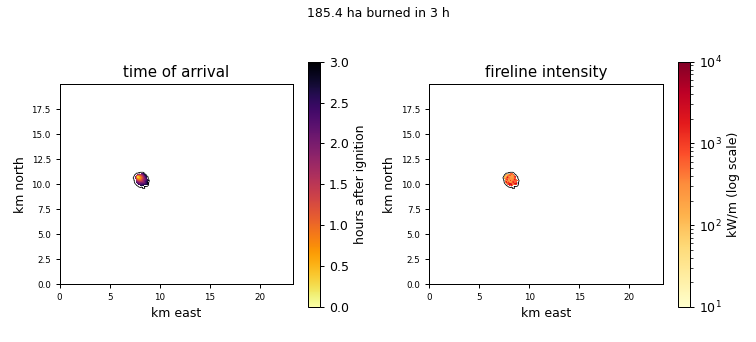
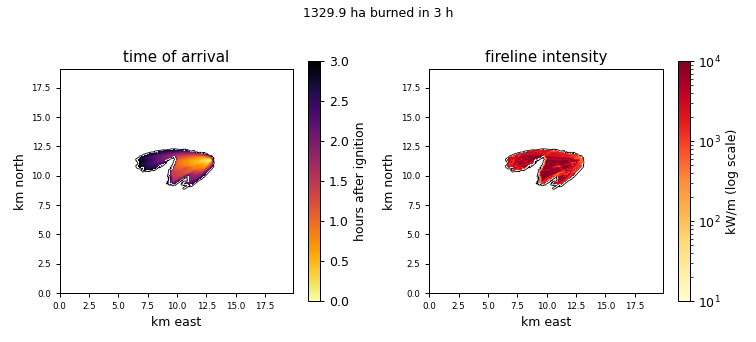
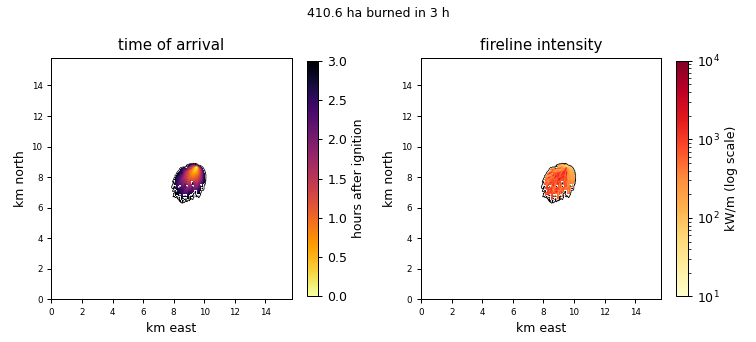
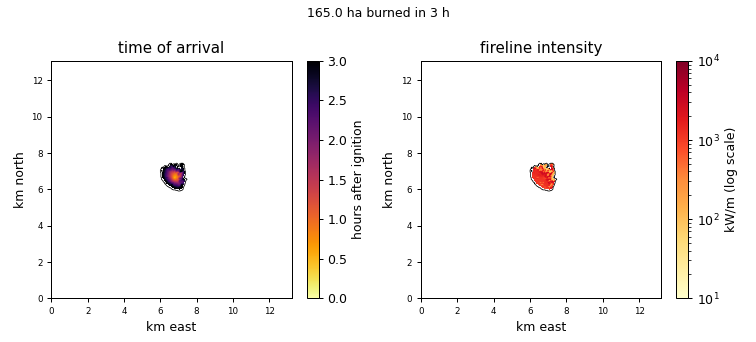

https://wstc-dagster.nrp-nautilus.io/assets/apearce/elmfire_reported_ignition/prediction


In [12]:
previews = {}
for fire, v in runs.items():
    for asset, md in d.results(v["run_id"]).items():
        if asset.endswith("/prediction") and "preview" in md:
            previews[fire] = md["preview"]
show_previews(previews)
print(f"{d.url}/assets/{ME}/{cp['workflow']}/prediction")

Every prediction's rasters are also in S3, under the same identity path as on the shared volume, so the actual model output (the time-of-arrival GeoTIFF, not just a picture) outlives the server. Dagster's UI has a download link on each prediction; the notebook shows only where it is, since those links carry the bucket's key ID and expire after a day.

In [13]:
download_links({fire: d.results(v["run_id"]) for fire, v in runs.items()})

| fire | s3 | location | files |
|---|---|---|---|
| hughes | already in S3 | `s3://wstc-dagster/apearce/bench/artifacts/hughes/runs/elmfire-448fd60ec6/` | time_of_arrival.tif, preview.png |
| kenneth | already in S3 | `s3://wstc-dagster/apearce/bench/artifacts/kenneth/runs/elmfire-2f3725e761/` | time_of_arrival.tif, preview.png |
| madre | already in S3 | `s3://wstc-dagster/apearce/bench/artifacts/madre/runs/elmfire-ba7da1e576/` | time_of_arrival.tif, preview.png |
| sandia | already in S3 | `s3://wstc-dagster/apearce/bench/artifacts/sandia/runs/elmfire-bf6535ef4f/` | time_of_arrival.tif, preview.png |

### Where to look in Dagster

* **Assets > apearce > elmfire_reported_ignition > prediction**: the partitions are the fires; any numeric field is charted across them.
* Every materialization records its identity, the artifact path, the run that built it, whether it was reused, where it is in S3, and the block's full summary.
* **Runs** has every launch with its logs, including each block's own output.

## 9. A second modeling workflow

`elmfire_ngfs_ignition.yaml` is the same recipe with one change: the ignition is the fire's first NGFS (GOES) detection instead of the reported origin. It is a different modeling workflow, because it is a different recipe. Three things to see:

* it **shares** every artifact that doesn't depend on the ignition (LANDFIRE, the roads override, the wind, the moisture), so those are reused, not rebuilt;
* all four cases have an NGFS point, so it runs for all of them. A case without one would be **unavailable** for this recipe, with the reason, instead of failing;
* benchmarking both against the same references gives the **scoring matrix**: one row per modeling workflow, one column per fire. Since the two differ only in the ignition, any difference in a column comes from the ignition source alone.

In [14]:
WORKFLOW_2 = REPO / "workflows" / "elmfire_ngfs_ignition.yaml"
wf_file_2, cp_2 = wstc.build_workflow_file(WORKFLOW_2, FIRES, ME, BUILD, IMAGES)
jobs_2 = wstc.job_names(ME, cp_2["workflow"])
shared_with(cp, cp_2, sorted(cp["fires"])[0])

| step | identity | shared |
|---|---|---|
| landscape.landfire | ebe22ed133 | yes, built once |
| landscape.roads_override | bdec15e267 | yes, built once |
| weather.station_wind | 0611023d0c | yes, built once |
| moisture.fixed_moisture | 2f99900062 | yes, built once |
| ignition.case_ignition | 44635a5124 | no |
| ignition.auto_reproject | 226464c66d | no |

In [21]:
d.upload(str(wf_file_2))
runs_2 = run_fires(d, jobs_2["run"], sorted(cp_2["fires"]), tags={"bench/lfps_email": LFPS_EMAIL})
run_id, status, res = d.run(jobs_2["report"])
rep_2 = next(md for a, md in res.items() if a.endswith("/report"))
md_table(rep_2["rows"])

launched hughes
launched kenneth
launched madre
SUCCESS  hughes  (218 s)
launched sandia
SUCCESS  madre  (247 s)
SUCCESS  kenneth  (366 s)
SUCCESS  sandia  (423 s)


| area_bias | burned_ha_end_of_run | fire | iou | observed_ha | predicted_ha | scored_at_min | status |
|---|---|---|---|---|---|---|---|
| -0.475 | 1521.7 | hughes | 0.3297 | 2040.5 | 1071.3 | 147.1 | done |
| -0.1885 | 399.6 | kenneth | 0.3073 | 388.3 | 315.1 | 164.8 | done |
| -0.9596 | 175.9 | madre | 0.0374 | 3398.7 | 137.2 | 160.8 | done |
| 0.5797 | 121.0 | sandia | 0.1447 | 12.4 | 19.6 | 117.9 | done |

### The scoring matrix

Each cell is the score of one modeling workflow on one fire, or why there is none (*unavailable*, *not scored*, with the reason).

In [23]:
reports = {cp["workflow"]: rep["rows"], cp_2["workflow"]: rep_2["rows"]}
fires = sorted(cp["fires"])
display(Markdown("**IoU** (1 = perfect overlap)"), scoring_matrix(reports, "iou", fires))
display(Markdown("**Area bias** (0 = right size, -0.5 = half the observed area)"), scoring_matrix(reports, "area_bias", fires))

**IoU** (1 = perfect overlap)

| modeling workflow | hughes | kenneth | madre | sandia |
|---|---|---|---|---|
| elmfire_reported_ignition | 0.3546 | 0.245 | 0.0378 | 0.1825 |
| elmfire_ngfs_ignition | 0.3297 | 0.3073 | 0.0374 | 0.1447 |

**Area bias** (0 = right size, -0.5 = half the observed area)

| modeling workflow | hughes | kenneth | madre | sandia |
|---|---|---|---|---|
| elmfire_reported_ignition | -0.5329 | -0.1834 | -0.9608 | 2.3188 |
| elmfire_ngfs_ignition | -0.475 | -0.1885 | -0.9596 | 0.5797 |

### Reading the matrix

The two modeling workflows differ only in the ignition, so each column shows what the ignition source alone did on that fire:

* **Kenneth**: IoU 0.25 to 0.31. The satellite detection puts the start closer to where the fire actually went.
* **Sandia**: area bias 2.32 to 0.58, IoU 0.18 to 0.14. On a small fire, a different start point changes the footprint a lot: closer to the right size, less overlap.
* **Hughes** and **Madre**: almost unchanged. For large wind-driven runs, a couple of hundred meters of ignition location barely matters; something else dominates.

(The two sources also differ by a few minutes in time, so this mixes where with when; separating the two is on the list in `docs/TODO.md`.)


## 10. Models we don't run

Benchmarking needs one thing from a model: its fire rasters. So a model doesn't have to run here to be benchmarked. A group whose model is proprietary, or simply not packaged as a block, can **submit** its predictions instead: for each fire, the area it predicts burned at each time, as timed perimeters, and nothing else (no model, no inputs, no settings).

How it works (`submissions/README.md`):

* `bench.submit` puts a submission in the S3 bucket, one GeoJSON per fire (only pods have S3 credentials, so the upload is itself a small Dagster job). A version, once there, is immutable.
* A modeling workflow reads it with the **`submitted_perimeters`** source, which records where it came from and its checksum, and the **`perimeter_replay`** "model" turns the perimeters into fire rasters: a cell's arrival time is the first perimeter that contains it, so arrival times are as coarse as the submission's time step.
* From there, benchmarking is exactly the same: same references, same metrics, same table, one more row in the scoring matrix.

This path is tested end to end (submission to S3, replay, conventions check, the same metrics) with a third-party model's perimeters for these fires; those results aren't ours to publish, so they are not shown here.


### Open models, closed models

Benchmarking needs one thing from a model: its prediction, as fire rasters on the case grid. So any model can be scored, whether we run it, a colleague shares it, or a vendor only sends perimeters. Every one is scored the same way, against the same references, at the same observation times.

What openness changes is what we can say *besides* the score. A submitted model is a black box: its lineage ends at the submission (where it is in S3, its checksum), and its row in the scoring matrix can only be compared as a whole. For ELMFIRE, every input and method is a block, so two workflows that differ in one thing (the ignition source) show exactly what that one thing did. An open model can be rerun on a new fire or with a corrected input; a closed one can only be resubmitted. And we can guarantee that our modeling workflows never saw the observations they are scored against; for a submission we can't, and its rows say so.

So the framework supports closed models fully and favors open ones naturally: openness doesn't earn a better score, it earns an explanation.


## 11. What is real so far

| Part | Status |
|---|---|
| LANDFIRE 2024 fuels and canopy, LF 2020 elevation | real, from the LANDFIRE Product Service |
| Roads/urban override to GR2 | real |
| Station wind (nearest ASOS with data, hourly) | real, from the Iowa Environmental Mesonet (the nearest station with data; Sandberg, SDB, for Hughes); uniform over the domain (no WindNinja yet) |
| Fuel moisture | a fixed scenario value (1 h dead = 6%), other classes at the adapter's reported defaults |
| Ignition: reported origin | real (the WIFIRE fire groupings geopackage, Centers layer) |
| Ignition: NGFS first detection | real (the same geopackage, NGFS layer) |
| ELMFIRE (pyretechnics) | real, in its own image |
| FARSITE, WindNinja, WRF-Fire | manifests only: a workflow naming them is rejected by the resolver with the reason |
| Reference perimeter, IoU, area bias | real: FIRIS perimeters, scored at their observation time |
| Fires | four real cases from the WIFIRE Consolidated Fire Groupings 2025 geopackage, written by hand |
| Models we don't run | submitted perimeters from S3, replayed and benchmarked like the rest (submission, replay and scoring tested end to end) |
| Artifact store | the WSTC shared volume, with every finished artifact copied to S3 (write-through) |

Next: benchmarking as its own workflow, separate from the modeling workflows, so any fire rasters (including ones submitted from outside) are scored the same way; a case catalog built from the geopackage; more metrics (`docs/metrics_contract.md`); reads and reuse from S3. See `docs/next_steps.md`.

### Cleanup (optional)

Removes our files from the server; the jobs and assets disappear with them. Artifacts on the shared volume stay, so a later upload reuses them.

In [ ]:
# d.remove(wf_file.name); d.remove(wf_file_2.name)